# Model comparison and best-model selection

Compare the four optimized models. Select the highest validation accuracy among fitting-eligible models; exact ties use CV accuracy, then name. Test scores are reported afterward and never determine selection.

In [1]:
from pathlib import Path
import sys, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/model_workflow.py').exists())
sys.path.insert(0,str(root/'src'))
from model_workflow import paths,load_features,matrix,TARGET,metrics
folder=root/'outputs/final_four'
selection=json.loads((folder/'selection.json').read_text())
comparison=pd.read_csv(folder/'accuracy_summary.csv')
assert len(comparison)==4 and set(comparison.Model)=={'logistic_regression','decision_tree','random_forest','gradient_boosting'}
data,fingerprint=load_features(paths(root)['processed'])
assert fingerprint==selection['fingerprint'], 'Data changed: revalidate models.'
audit=pd.read_csv(root/'outputs/evidence/optimization/fitting_audit.csv').set_index('Model')
for _,row in comparison.iterrows():
    bundle=joblib.load(folder/f'{row.Model}.joblib')
    assert bundle['metadata']['fingerprint']==fingerprint
    assert bundle['metadata']['Threshold']==row.Threshold
    for split,column in [('train','Training accuracy'),('validation','Validation accuracy')]:
        part=data[data.split.eq(split)]
        actual=metrics(row.Model,part[TARGET],bundle['pipeline'].predict_proba(matrix(part))[:,1],row.Threshold)['Accuracy']
        assert np.isclose(actual,row[column])
comparison['Fit eligible']=comparison.Source.map(audit['Pass'])
eligible=comparison[comparison['Fit eligible']].sort_values(['Validation accuracy','CV accuracy','Model'],ascending=[False,False,True])
if eligible.empty: raise ValueError('No eligible model. Do not select an unsafe fallback.')
winner=eligible.iloc[0]
assert winner.Model==selection['model'], 'Selection mismatch: review final artifacts.'
display(Markdown(f"## Best model by validation: **{winner.Model.replace('_',' ').title()}**\nValidation accuracy: **{winner['Validation accuracy']:.2%}**."))

## Best model by validation: **Random Forest**
Validation accuracy: **68.63%**.

## Accuracy comparison

Training, validation and test scores use each model’s frozen prediction threshold. Test results are descriptive reused-holdout estimates.

In [2]:
for _,row in comparison.iterrows():
    bundle=joblib.load(folder/f'{row.Model}.joblib')
    part=data[data.split.eq('test')]
    actual=metrics(row.Model,part[TARGET],bundle['pipeline'].predict_proba(matrix(part))[:,1],row.Threshold)['Accuracy']
    assert np.isclose(actual,row['Test accuracy'])
comparison['Selected']=comparison.Model.eq(winner.Model)
comparison=comparison.sort_values(['Validation accuracy','CV accuracy','Model'],ascending=[False,False,True])
columns=['Model','Training accuracy','Validation accuracy','Test accuracy','CV accuracy','Threshold-matched CV gap','Train-test gap','Fit eligible','Selected']
display(comparison[columns].style.format({c:'{:.2%}' for c in columns if 'accuracy' in c or 'gap' in c}))
comparison.to_csv(folder/'model_comparison.csv',index=False)
test_leader=comparison.sort_values('Test accuracy',ascending=False).iloc[0]
print(f"Highest observed test accuracy: {test_leader.Model} ({test_leader['Test accuracy']:.2%}).")
print('Test ranking does not change the validation-selected winner.')

,Model,Training accuracy,Validation accuracy,Test accuracy,CV accuracy,Threshold-matched CV gap,Train-test gap,Fit eligible,Selected
2,random_forest,71.56%,68.63%,67.12%,69.59%,4.15%,4.43%,True,True
0,logistic_regression,68.67%,68.29%,67.37%,69.18%,0.81%,1.30%,True,False
3,gradient_boosting,67.21%,67.88%,65.88%,69.54%,2.40%,1.33%,True,False
1,decision_tree,65.28%,66.10%,65.69%,68.22%,1.16%,-0.41%,True,False


Highest observed test accuracy: logistic_regression (67.37%).
Test ranking does not change the validation-selected winner.


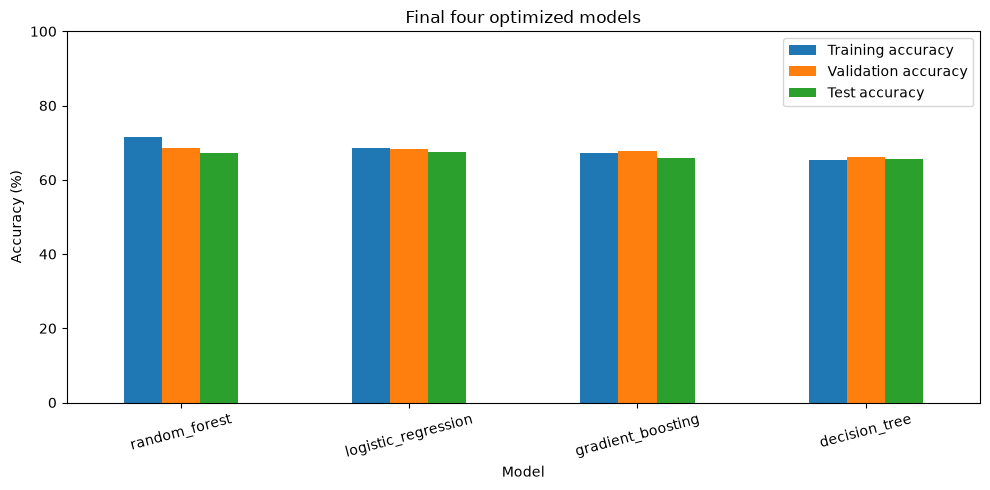

In [3]:
plot=comparison.set_index('Model')[['Training accuracy','Validation accuracy','Test accuracy']]*100
ax=plot.plot.bar(figsize=(10,5),ylim=(0,100),rot=15)
ax.set_ylabel('Accuracy (%)')
ax.set_title('Final four optimized models')
plt.tight_layout()
plt.show()

## Fitting and reliability

All four retained models pass the existing fitting screens, including customer-disjoint CV. The 5-percentage-point gap rule is a heuristic, not proof of zero overfitting or underfitting. Small ranking differences do not establish statistical superiority. Validation and test have been inspected repeatedly; fresh future data is needed to confirm generalization. This notebook verifies the frozen selection without switching models based on test scores.